# Lab Mid Exam — HOG vs SIFT on Blood-Cell Images
**Computer Vision Lab**  |  Time: 90 min  |  Total: 25 marks

| Field | Value |
|-------|-------|
| **Name** | Abdul Rehman |
| **Roll No** | FA23-BAI-036 |
| **Seed** | 36 (last two digits of 036) |
| **HOG Cell Size** | **8 × 8** px  *(last digit = 6, EVEN → 8×8)* |
| **SIFT Grid** | **6 × 6 = 36 keypoints**  *(last digit = 6, in [5–9])* |

---


## ⚙️ Setup — Install Libraries *(run once, restart runtime after)*

In [1]:
# ── Install required libraries ──────────────────────────────────────────────
# Run this cell FIRST, then go to Runtime → Restart Runtime, then run all cells
!pip install medmnist scikit-image scikit-learn -q
print("Installation complete. Please restart the runtime before continuing.")


Installation complete. Please restart the runtime before continuing.


## 📦 Imports & Personal Settings

In [2]:
# ── Standard imports ────────────────────────────────────────────────────────
import numpy as np
import matplotlib.pyplot as plt
import cv2
from skimage.feature import hog as sk_hog
from skimage import exposure
from sklearn.svm import LinearSVC
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay
)
from medmnist import BloodMNIST
import warnings
warnings.filterwarnings('ignore')

# ── Personal settings derived from FA23-BAI-036 ─────────────────────────────
ROLL       = "FA23-BAI-036"
NAME       = "Abdul Rehman"
SEED       = 36           # last two digits of 036
HOG_CELL   = (8, 8)       # last digit = 6  →  EVEN  →  8×8 px
SIFT_GRID  = 6            # last digit = 6  →  in [5-9]  →  6×6 = 36 keypoints

# ── Fixed exam settings ─────────────────────────────────────────────────────
IMG_SIZE   = 128          # resize all images to 128×128
CLASSES    = [1, 5, 6, 7] # eosinophil, monocyte, neutrophil, platelet
CNAMES     = {
    1: 'eosinophil',
    5: 'monocyte',
    6: 'neutrophil',
    7: 'platelet'
}
TRAIN_N    = 100          # images per class in training set
VAL_N      = 30           # images per class in validation set
TEST_N     = 30           # images per class in test set

np.random.seed(SEED)

print(f"Student : {NAME}  ({ROLL})")
print(f"Seed    : {SEED}")
print(f"HOG cell: {HOG_CELL}  (8×8 because last digit 6 is EVEN)")
print(f"SIFT    : {SIFT_GRID}×{SIFT_GRID} = {SIFT_GRID**2} keypoints  (last digit 6 in [5-9])")


Student : Abdul Rehman  (FA23-BAI-036)
Seed    : 36
HOG cell: (8, 8)  (8×8 because last digit 6 is EVEN)
SIFT    : 6×6 = 36 keypoints  (last digit 6 in [5-9])


---
## Q1 — Data Setup  *(3 marks)*

**Task:** Load the BloodMNIST dataset, keep only 4 classes (1, 5, 6, 7),
sample the required number of images per class from each split using `seed=36`,
convert to 128×128 grayscale, and display a visual grid.


In [3]:
# ── Q1-A: Download BloodMNIST and sample per-class subsets ──────────────────

ds_train = BloodMNIST(split='train', download=True, size=64)
ds_val   = BloodMNIST(split='val',   download=True, size=64)
ds_test  = BloodMNIST(split='test',  download=True, size=64)

def sample_subset(dataset, classes, n_per_class, seed):
    """
    Sample exactly n_per_class images per class from a BloodMNIST split.
    Uses a fixed RandomState so results are reproducible.
    Returns:
        imgs : uint8 array (N_total, H, W, 3)
        labels: int array  (N_total,)
    """
    rng    = np.random.RandomState(seed)
    imgs   = dataset.imgs            # (N, 64, 64, 3)
    labels = dataset.labels.flatten()
    X_out, y_out = [], []
    for cls in classes:
        idx  = np.where(labels == cls)[0]
        # allow replacement only if the class has fewer samples than needed
        replace = len(idx) < n_per_class
        chosen  = rng.choice(idx, n_per_class, replace=replace)
        X_out.append(imgs[chosen])
        y_out.extend([cls] * n_per_class)
    return np.concatenate(X_out, axis=0), np.array(y_out)

def to_gray128(imgs_rgb):
    """Convert (N, 64, 64, 3) RGB uint8 → (N, 128, 128) grayscale uint8."""
    result = []
    for img in imgs_rgb:
        gray    = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
        resized = cv2.resize(gray, (IMG_SIZE, IMG_SIZE))
        result.append(resized)
    return np.array(result, dtype=np.uint8)

# ── Sample all three splits ──────────────────────────────────────────────────
Xtr_rgb, ytr = sample_subset(ds_train, CLASSES, TRAIN_N, SEED)
Xvl_rgb, yvl = sample_subset(ds_val,   CLASSES, VAL_N,   SEED)
Xte_rgb, yte = sample_subset(ds_test,  CLASSES, TEST_N,  SEED)

# ── Convert to grayscale 128×128 ────────────────────────────────────────────
Xtr = to_gray128(Xtr_rgb)   # shape (400, 128, 128)
Xvl = to_gray128(Xvl_rgb)   # shape (120, 128, 128)
Xte = to_gray128(Xte_rgb)   # shape (120, 128, 128)

# ── Print shapes and per-class counts ───────────────────────────────────────
for split_name, X, y in [('Train', Xtr, ytr), ('Val', Xvl, yvl), ('Test', Xte, yte)]:
    print(f"\n{split_name}: images={X.shape}  labels={y.shape}")
    for cls in CLASSES:
        print(f"  Class {cls} ({CNAMES[cls]:<14}): {int((y == cls).sum())}")


100%|██████████| 156M/156M [01:26<00:00, 1.81MB/s]



Train: images=(400, 128, 128)  labels=(400,)
  Class 1 (eosinophil    ): 100
  Class 5 (monocyte      ): 100
  Class 6 (neutrophil    ): 100
  Class 7 (platelet      ): 100

Val: images=(120, 128, 128)  labels=(120,)
  Class 1 (eosinophil    ): 30
  Class 5 (monocyte      ): 30
  Class 6 (neutrophil    ): 30
  Class 7 (platelet      ): 30

Test: images=(120, 128, 128)  labels=(120,)
  Class 1 (eosinophil    ): 30
  Class 5 (monocyte      ): 30
  Class 6 (neutrophil    ): 30
  Class 7 (platelet      ): 30


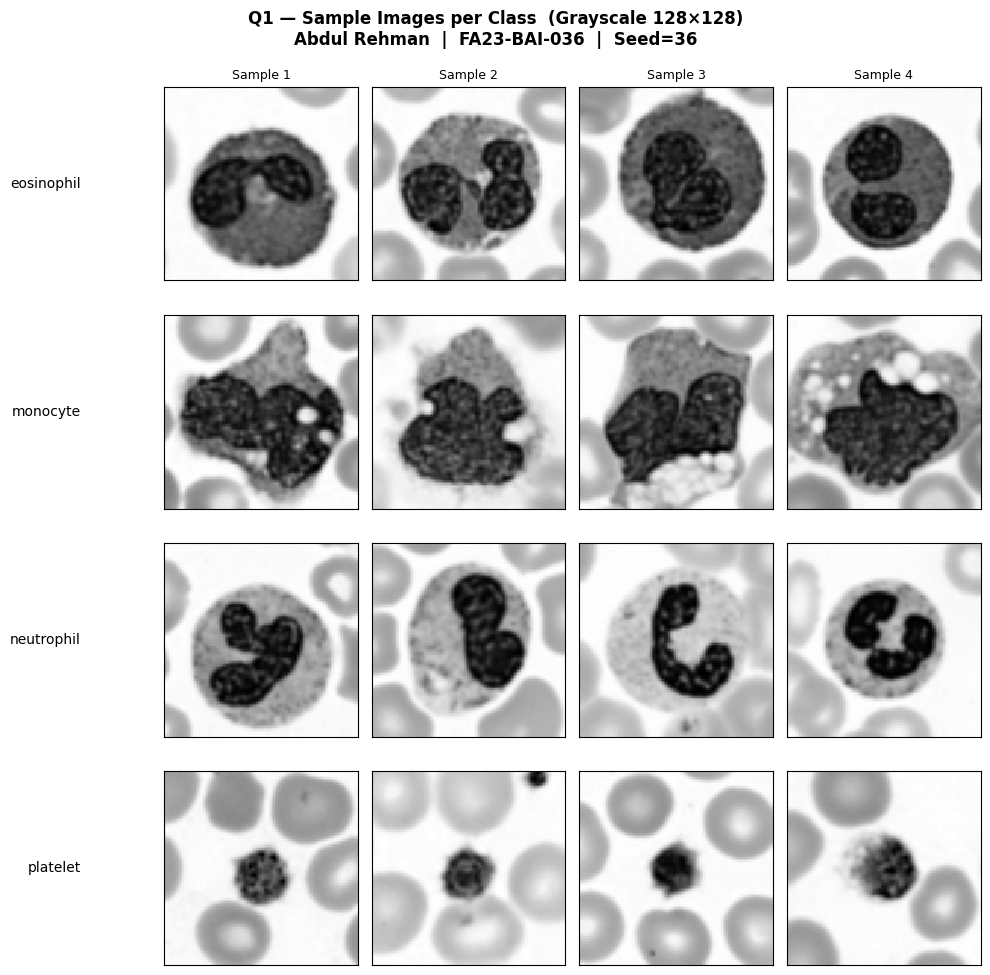

Q1 complete.


In [4]:
# ── Q1-B: Visualise — 4 sample images per class ─────────────────────────────

fig, axes = plt.subplots(4, 4, figsize=(10, 10))
fig.suptitle(
    'Q1 — Sample Images per Class  (Grayscale 128×128)\n'
    f'{NAME}  |  {ROLL}  |  Seed={SEED}',
    fontsize=12, fontweight='bold'
)

for row, cls in enumerate(CLASSES):
    class_idxs = np.where(ytr == cls)[0][:4]
    for col, idx in enumerate(class_idxs):
        ax = axes[row, col]
        ax.imshow(Xtr[idx], cmap='gray', interpolation='nearest')
        ax.set_xticks([]); ax.set_yticks([])
        if col == 0:
            ax.set_ylabel(CNAMES[cls], fontsize=10,
                          rotation=0, ha='right', va='center', labelpad=60)
        if row == 0:
            ax.set_title(f'Sample {col+1}', fontsize=9)

plt.tight_layout()
plt.show()
print("Q1 complete.")


---
## Q2 — HOG Feature Extraction + SVM Classifier  *(6 marks)*

### Hand Calculation — HOG Feature Vector Length

| Parameter | Rule / Calculation | Value |
|-----------|-------------------|-------|
| Image size | fixed | 128 × 128 px |
| Cell size *(my setting — digit 6 is EVEN)* | even → 8×8 | **8 × 8 px** |
| Cells per row & col | 128 ÷ 8 | **16** |
| Block size | 2 × 2 cells | 16 × 16 px |
| Block stride | 1 cell = 8 px | 8 px |
| Blocks per row & col | 16 − 2 + 1 | **15** |
| Total blocks | 15 × 15 | **225** |
| Bins per block | 2 × 2 cells × 9 orientation bins | **36** |
| **Total HOG features** | 225 × 36 | **8 100** |

> **Note:** The 8×8 cell is smaller than 16×16, so gradients are pooled over fewer pixels per bin.
> This gives finer spatial resolution but a much longer feature vector (8 100 vs 1 764).


In [5]:
# ── Q2-A: Extract HOG features for every image ──────────────────────────────

def extract_hog(images):
    """
    Compute HOG descriptor for each image.
    Settings:
        pixels_per_cell = HOG_CELL = (8, 8)   [personal setting: digit 6 is EVEN]
        cells_per_block = (2, 2)
        orientations    = 9
        block_norm      = 'L2-Hys'
    Returns float64 array of shape (N, feature_length).
    """
    feats = []
    for img in images:
        f = sk_hog(
            img,
            orientations=9,
            pixels_per_cell=HOG_CELL,        # (8, 8)
            cells_per_block=(2, 2),
            block_norm='L2-Hys',
            visualize=False
        )
        feats.append(f)
    return np.array(feats)

# Extract features for all three splits
Fhog_tr = extract_hog(Xtr)
Fhog_vl = extract_hog(Xvl)
Fhog_te = extract_hog(Xte)

hog_len = Fhog_tr.shape[1]
print(f"HOG feature length (actual) : {hog_len}")
print(f"HOG feature length (expected): 225 × 36 = {225*36}")
assert hog_len == 8100, f"ERROR: expected 8100, got {hog_len}"
print("✓ Feature length matches hand calculation.")


HOG feature length (actual) : 8100
HOG feature length (expected): 225 × 36 = 8100
✓ Feature length matches hand calculation.


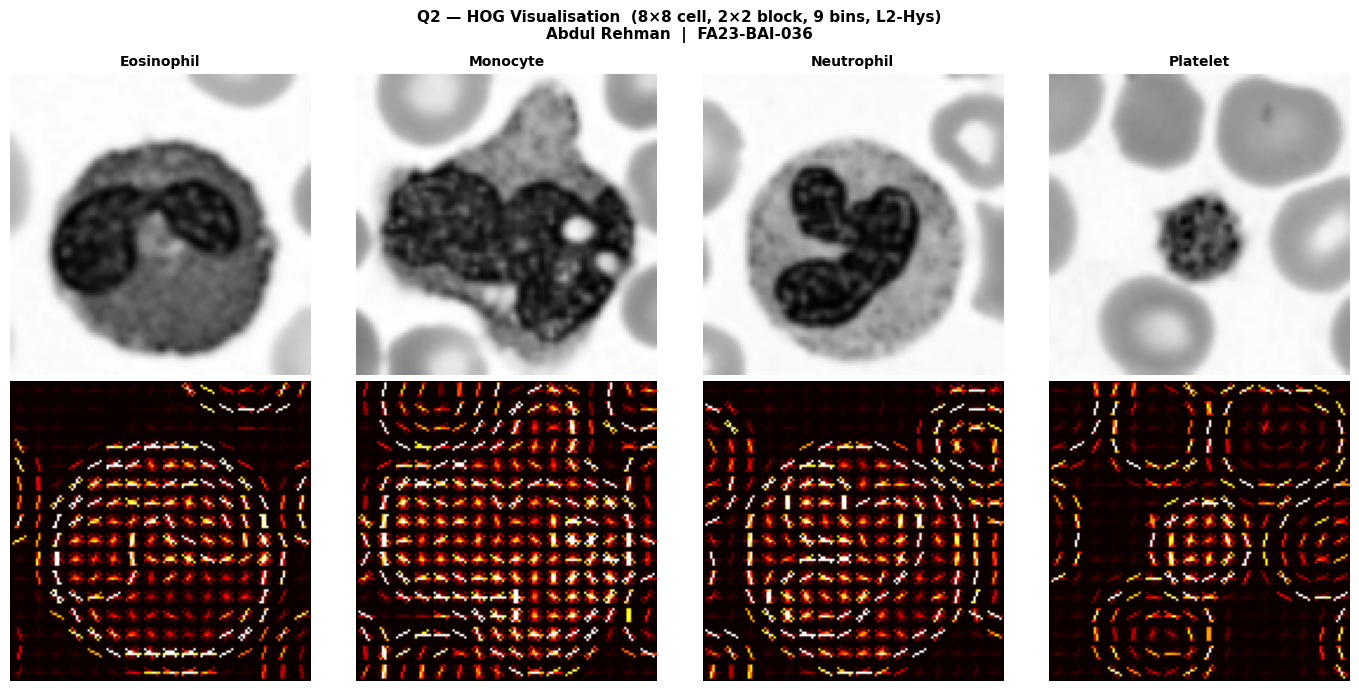

In [6]:
# ── Q2-B: Visualise HOG gradient maps — one image per class ─────────────────

fig, axes = plt.subplots(2, 4, figsize=(14, 7))
fig.suptitle(
    'Q2 — HOG Visualisation  (8×8 cell, 2×2 block, 9 bins, L2-Hys)\n'
    f'{NAME}  |  {ROLL}',
    fontsize=11, fontweight='bold'
)

for col, cls in enumerate(CLASSES):
    idx = np.where(ytr == cls)[0][0]
    img = Xtr[idx]

    _, hog_img = sk_hog(
        img,
        orientations=9,
        pixels_per_cell=HOG_CELL,
        cells_per_block=(2, 2),
        block_norm='L2-Hys',
        visualize=True
    )
    hog_img_scaled = exposure.rescale_intensity(hog_img, in_range=(0, 10))

    # Row 0: original grayscale
    axes[0, col].imshow(img, cmap='gray')
    axes[0, col].set_title(CNAMES[cls].capitalize(), fontsize=10, fontweight='bold')
    axes[0, col].axis('off')

    # Row 1: HOG gradient map
    axes[1, col].imshow(hog_img_scaled, cmap='hot')
    axes[1, col].axis('off')

axes[0, 0].set_ylabel('Original', fontsize=10, rotation=0,
                       ha='right', va='center', labelpad=55)
axes[1, 0].set_ylabel('HOG Map',  fontsize=10, rotation=0,
                       ha='right', va='center', labelpad=55)
plt.tight_layout()
plt.show()


HOG+SVM — Validation accuracy for each C value:
----------------------------------------
  C =  0.01  →  val accuracy = 0.7583
  C =   0.1  →  val accuracy = 0.7583
  C =     1  →  val accuracy = 0.7583
  C =    10  →  val accuracy = 0.7583

Best C selected: 0.01  (val acc = 0.7583)

Final HOG+SVM  (C=0.01)
  Validation Accuracy : 0.7583
  Validation Macro-F1 : 0.7587

Confusion Matrix (rows=true class, cols=predicted class):
Classes: ['eosinophil', 'monocyte', 'neutrophil', 'platelet']
[[18  8  4  0]
 [ 5 24  1  0]
 [ 4  6 20  0]
 [ 0  0  1 29]]


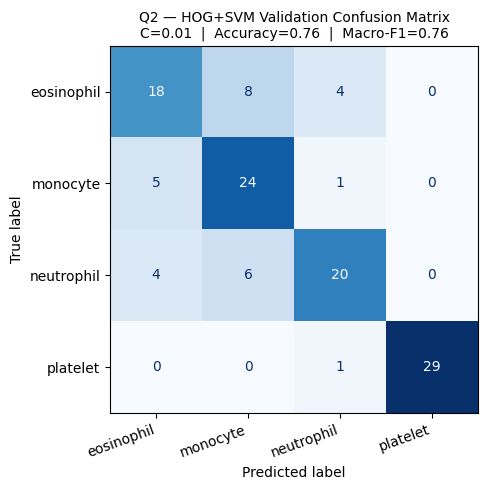

In [7]:
# ── Q2-C: Scale features and train LinearSVC; select C on validation set ─────

scaler_hog = StandardScaler()
Fhog_tr_s  = scaler_hog.fit_transform(Fhog_tr)
Fhog_vl_s  = scaler_hog.transform(Fhog_vl)
Fhog_te_s  = scaler_hog.transform(Fhog_te)

print("HOG+SVM — Validation accuracy for each C value:")
print("-" * 40)

best_C_hog, best_val_acc_hog = None, -1
for C in [0.01, 0.1, 1, 10]:
    clf = LinearSVC(C=C, random_state=SEED, max_iter=5000)
    clf.fit(Fhog_tr_s, ytr)
    val_acc = accuracy_score(yvl, clf.predict(Fhog_vl_s))
    print(f"  C = {C:5g}  →  val accuracy = {val_acc:.4f}")
    if val_acc > best_val_acc_hog:
        best_val_acc_hog, best_C_hog = val_acc, C

print(f"\nBest C selected: {best_C_hog}  (val acc = {best_val_acc_hog:.4f})")

# Retrain final model with best C
hog_clf   = LinearSVC(C=best_C_hog, random_state=SEED, max_iter=5000)
hog_clf.fit(Fhog_tr_s, ytr)

# Evaluate on validation set
yhat_hog_vl  = hog_clf.predict(Fhog_vl_s)
hog_val_acc  = accuracy_score(yvl, yhat_hog_vl)
hog_val_f1   = f1_score(yvl, yhat_hog_vl, average='macro')
cm_hog_val   = confusion_matrix(yvl, yhat_hog_vl, labels=CLASSES)

print(f"\nFinal HOG+SVM  (C={best_C_hog})")
print(f"  Validation Accuracy : {hog_val_acc:.4f}")
print(f"  Validation Macro-F1 : {hog_val_f1:.4f}")
print(f"\nConfusion Matrix (rows=true class, cols=predicted class):")
print("Classes:", [CNAMES[c] for c in CLASSES])
print(cm_hog_val)

# Plot confusion matrix
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(
    cm_hog_val,
    display_labels=[CNAMES[c] for c in CLASSES]
).plot(ax=ax, cmap='Blues', colorbar=False)
ax.set_title(
    f'Q2 — HOG+SVM Validation Confusion Matrix\n'
    f'C={best_C_hog}  |  Accuracy={hog_val_acc:.2f}  |  Macro-F1={hog_val_f1:.2f}',
    fontsize=10
)
plt.xticks(rotation=20, ha='right')
plt.tight_layout()
plt.show()


---
## Q3 — SIFT Feature Extraction + SVM Classifier  *(7 marks)*

### Hand Calculation — Fixed-Grid SIFT Feature Vector Length

| Parameter | Rule / Calculation | Value |
|-----------|-------------------|-------|
| Grid size *(my setting — digit 6 in [5–9])* | 6×6 | **36 keypoints** |
| SIFT descriptor size | fixed by algorithm | **128** dimensions |
| **Total SIFT features** | 36 × 128 | **4 608** |

### Why Variable Keypoint Count Breaks SVM

> Standard SIFT *detects* keypoints based on local extrema in scale-space —
> different images yield different numbers of keypoints (e.g., 12 on one image, 340 on another).
> An SVM needs **one fixed-length vector per sample** so it can form the matrix
> `X ∈ ℝ^{N × d}`.
> With variable keypoints, `d` changes per sample — `LinearSVC.fit()` would receive
> rows of different lengths and immediately raise a `ValueError`.
> **Solution:** place keypoints on a regular 6×6 grid so every image always
> contributes exactly 36 descriptors → 36 × 128 = 4 608 features.


Standard SIFT keypoint statistics on training set:
  Min keypoints per image : 9
  Max keypoints per image : 178
  Mean                    : 69.8
  Images with 0 keypoints : 0

→ Keypoint count varies from 9 to 178
→ Cannot form a fixed-size feature matrix → SVM would fail.


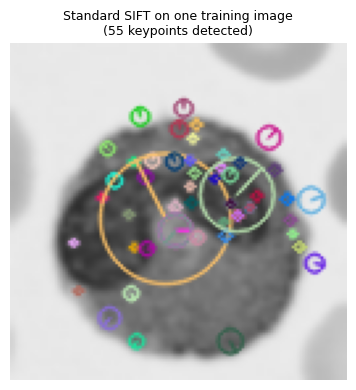

In [8]:
# ── Q3-A: Standard SIFT detection — show variable keypoint problem ───────────

sift = cv2.SIFT_create()

kp_counts = []
for img in Xtr:
    kps, _ = sift.detectAndCompute(img, None)
    kp_counts.append(len(kps))
kp_counts = np.array(kp_counts)

print("Standard SIFT keypoint statistics on training set:")
print(f"  Min keypoints per image : {kp_counts.min()}")
print(f"  Max keypoints per image : {kp_counts.max()}")
print(f"  Mean                    : {kp_counts.mean():.1f}")
print(f"  Images with 0 keypoints : {(kp_counts == 0).sum()}")
print(f"\n→ Keypoint count varies from {kp_counts.min()} to {kp_counts.max()}")
print("→ Cannot form a fixed-size feature matrix → SVM would fail.")

# Draw keypoints on the first image
sample_img = Xtr[0]
kps0, _    = sift.detectAndCompute(sample_img, None)
kp_drawn   = cv2.drawKeypoints(
    sample_img, kps0, None,
    flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS
)

plt.figure(figsize=(4, 4))
plt.imshow(kp_drawn)
plt.title(f'Standard SIFT on one training image\n({len(kps0)} keypoints detected)',
          fontsize=9)
plt.axis('off')
plt.tight_layout()
plt.show()


Grid keypoints created: 36  (6 × 6)
SIFT feature length (actual)  : 4608
SIFT feature length (expected): 36 × 128 = 4608
✓ Feature length matches hand calculation.


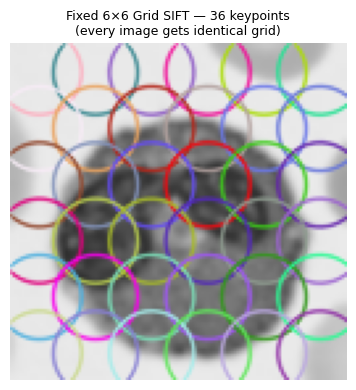

In [9]:
# ── Q3-B: Fixed-Grid SIFT — 6×6 = 36 keypoints per image ───────────────────

def build_grid_keypoints(grid=SIFT_GRID, img_size=IMG_SIZE, kp_size=32):
    """
    Place one cv2.KeyPoint at the centre of each cell in a
    (grid × grid) regular grid over an (img_size × img_size) image.
    kp_size controls the neighbourhood radius for descriptor computation.
    """
    step = img_size / grid
    kps  = []
    for r in range(grid):
        for c in range(grid):
            x = (c + 0.5) * step
            y = (r + 0.5) * step
            kps.append(cv2.KeyPoint(x=x, y=y, size=kp_size))
    return kps

GRID_KPS = build_grid_keypoints()
print(f"Grid keypoints created: {len(GRID_KPS)}  ({SIFT_GRID} × {SIFT_GRID})")

def extract_sift_grid(images):
    """
    Compute SIFT descriptors at fixed grid keypoints for each image.
    Returns float32 array of shape (N, SIFT_GRID² × 128).
    """
    feats = []
    for img in images:
        _, desc = sift.compute(img, GRID_KPS)
        if desc is None:
            desc = np.zeros((len(GRID_KPS), 128), dtype=np.float32)
        feats.append(desc.flatten())
    return np.array(feats, dtype=np.float32)

# Extract features
Fsift_tr = extract_sift_grid(Xtr)
Fsift_vl = extract_sift_grid(Xvl)
Fsift_te = extract_sift_grid(Xte)

sift_len = Fsift_tr.shape[1]
print(f"SIFT feature length (actual)  : {sift_len}")
print(f"SIFT feature length (expected): {SIFT_GRID**2} × 128 = {SIFT_GRID**2 * 128}")
assert sift_len == SIFT_GRID**2 * 128, f"ERROR: expected {SIFT_GRID**2*128}, got {sift_len}"
print("✓ Feature length matches hand calculation.")

# Visualise the fixed grid on one image
vis_img = cv2.cvtColor(Xtr[0], cv2.COLOR_GRAY2BGR)
vis_img = cv2.drawKeypoints(
    vis_img, GRID_KPS, None,
    flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS
)
plt.figure(figsize=(4, 4))
plt.imshow(vis_img)
plt.title(f'Fixed 6×6 Grid SIFT — {len(GRID_KPS)} keypoints\n(every image gets identical grid)',
          fontsize=9)
plt.axis('off')
plt.tight_layout()
plt.show()


SIFT+SVM — Validation accuracy for each C value:
----------------------------------------
  C =  0.01  →  val accuracy = 0.7583
  C =   0.1  →  val accuracy = 0.7500
  C =     1  →  val accuracy = 0.7500
  C =    10  →  val accuracy = 0.7500

Best C selected: 0.01  (val acc = 0.7583)

Final SIFT+SVM  (C=0.01)
  Validation Accuracy : 0.7583
  Validation Macro-F1 : 0.7538

Confusion Matrix (rows=true class, cols=predicted class):
Classes: ['eosinophil', 'monocyte', 'neutrophil', 'platelet']
[[16  7  7  0]
 [ 7 23  0  0]
 [ 3  3 22  2]
 [ 0  0  0 30]]


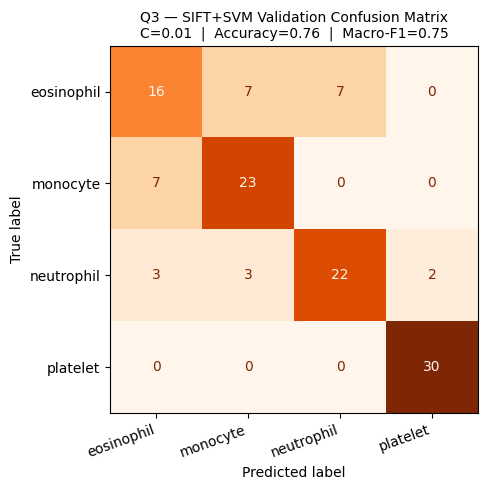

In [10]:
# ── Q3-C: Scale features and train LinearSVC; select C on validation set ─────

scaler_sift = StandardScaler()
Fsift_tr_s  = scaler_sift.fit_transform(Fsift_tr)
Fsift_vl_s  = scaler_sift.transform(Fsift_vl)
Fsift_te_s  = scaler_sift.transform(Fsift_te)

print("SIFT+SVM — Validation accuracy for each C value:")
print("-" * 40)

best_C_sift, best_val_acc_sift = None, -1
for C in [0.01, 0.1, 1, 10]:
    clf = LinearSVC(C=C, random_state=SEED, max_iter=5000)
    clf.fit(Fsift_tr_s, ytr)
    val_acc = accuracy_score(yvl, clf.predict(Fsift_vl_s))
    print(f"  C = {C:5g}  →  val accuracy = {val_acc:.4f}")
    if val_acc > best_val_acc_sift:
        best_val_acc_sift, best_C_sift = val_acc, C

print(f"\nBest C selected: {best_C_sift}  (val acc = {best_val_acc_sift:.4f})")

# Retrain final model
sift_clf = LinearSVC(C=best_C_sift, random_state=SEED, max_iter=5000)
sift_clf.fit(Fsift_tr_s, ytr)

# Evaluate on validation set
yhat_sift_vl  = sift_clf.predict(Fsift_vl_s)
sift_val_acc  = accuracy_score(yvl, yhat_sift_vl)
sift_val_f1   = f1_score(yvl, yhat_sift_vl, average='macro')
cm_sift_val   = confusion_matrix(yvl, yhat_sift_vl, labels=CLASSES)

print(f"\nFinal SIFT+SVM  (C={best_C_sift})")
print(f"  Validation Accuracy : {sift_val_acc:.4f}")
print(f"  Validation Macro-F1 : {sift_val_f1:.4f}")
print(f"\nConfusion Matrix (rows=true class, cols=predicted class):")
print("Classes:", [CNAMES[c] for c in CLASSES])
print(cm_sift_val)

# Plot confusion matrix
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(
    cm_sift_val,
    display_labels=[CNAMES[c] for c in CLASSES]
).plot(ax=ax, cmap='Oranges', colorbar=False)
ax.set_title(
    f'Q3 — SIFT+SVM Validation Confusion Matrix\n'
    f'C={best_C_sift}  |  Accuracy={sift_val_acc:.2f}  |  Macro-F1={sift_val_f1:.2f}',
    fontsize=10
)
plt.xticks(rotation=20, ha='right')
plt.tight_layout()
plt.show()


---
## Q4 — Robustness Testing  *(6 marks)*

### (1) Pre-run Predictions

**Rotation (20°) — which model will lose MORE accuracy?**

I predict **HOG+SVM** will suffer a larger accuracy drop under rotation.

*Reason:* HOG computes gradient histograms inside axis-aligned rectangular cells (8×8 px
in my case). A 20° rotation physically shifts the gradient orientations relative to these
fixed cells, so the gradient bin values change substantially, altering the feature vector.
SIFT descriptors are built relative to each keypoint's detected dominant orientation
(even in the fixed-grid variant), giving partial rotation invariance; the 128-D histogram
rotates with the patch, so it degrades more slowly.

**Noise (σ = 0.05) — which model will lose MORE accuracy?**

I predict **SIFT+SVM** will suffer a larger accuracy drop under Gaussian noise.

*Reason:* SIFT descriptors are computed from fine-grained local gradient orientations
over small sub-patches around each keypoint. Additive pixel noise directly corrupts these
orientation estimates, destabilising the 128-D descriptor. By contrast, HOG bins each
gradient over an entire 8×8 cell (64 pixels); the summed contribution of noise across
64 pixels largely cancels out, and the subsequent L2-Hys block normalisation further
attenuates small noise perturbations.


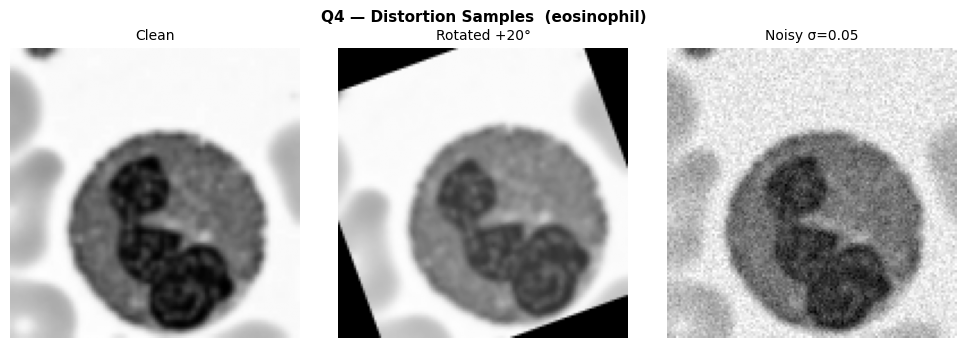


Model        |    Clean |     Rotated |      Noisy
HOG+SVM      |   0.7167 |      0.7000 |     0.2500
SIFT+SVM     |   0.7083 |      0.5333 |     0.7167

Accuracy drop  (Clean → Rotated  |  Clean → Noisy):
  HOG+SVM   : rotation drop = +0.0167  |  noise drop = +0.4667
  SIFT+SVM  : rotation drop = +0.1750  |  noise drop = -0.0083


In [11]:
# ── Q4: Apply distortions to test set — evaluate FROZEN models ──────────────
# IMPORTANT: both classifiers are frozen; no retraining happens here.

def rotate_images(images, angle=20):
    """Rotate every image by `angle` degrees about its centre."""
    cx, cy = IMG_SIZE / 2, IMG_SIZE / 2
    M = cv2.getRotationMatrix2D((cx, cy), angle, 1.0)
    return np.array(
        [cv2.warpAffine(img, M, (IMG_SIZE, IMG_SIZE)) for img in images]
    )

def add_gaussian_noise(images, sigma=0.05, seed=SEED):
    """Add Gaussian noise (sigma on [0,1] scale) to each image."""
    rng = np.random.RandomState(seed)
    out = []
    for img in images:
        img_f  = img.astype(np.float32) / 255.0
        noisy  = img_f + rng.normal(0, sigma, img_f.shape)
        noisy  = np.clip(noisy, 0.0, 1.0)
        out.append((noisy * 255).astype(np.uint8))
    return np.array(out)

# Create distorted test sets
Xte_rotated = rotate_images(Xte, angle=20)
Xte_noisy   = add_gaussian_noise(Xte, sigma=0.05)

# ── Visualise one sample of each distortion ──────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(10, 3.5))
sample_idx = np.where(yte == CLASSES[0])[0][0]
axes[0].imshow(Xte[sample_idx],         cmap='gray'); axes[0].set_title('Clean',       fontsize=10)
axes[1].imshow(Xte_rotated[sample_idx], cmap='gray'); axes[1].set_title('Rotated +20°', fontsize=10)
axes[2].imshow(Xte_noisy[sample_idx],   cmap='gray'); axes[2].set_title('Noisy σ=0.05', fontsize=10)
for ax in axes: ax.axis('off')
fig.suptitle('Q4 — Distortion Samples  (eosinophil)', fontsize=11, fontweight='bold')
plt.tight_layout(); plt.show()

# ── Evaluate function ─────────────────────────────────────────────────────────
def evaluate_on(clf, scaler, feat_fn, X_distorted, y_true):
    """Extract features → scale → predict → return accuracy."""
    F  = feat_fn(X_distorted)
    Fs = scaler.transform(F)
    return accuracy_score(y_true, clf.predict(Fs))

# ── Run all combinations ──────────────────────────────────────────────────────
variants = {
    'Clean'         : Xte,
    'Rotated (+20°)': Xte_rotated,
    'Noisy (σ=0.05)': Xte_noisy,
}

results = {}
for vname, Xv in variants.items():
    results[vname] = {
        'HOG+SVM' : evaluate_on(hog_clf,  scaler_hog,  extract_hog,       Xv, yte),
        'SIFT+SVM': evaluate_on(sift_clf, scaler_sift, extract_sift_grid, Xv, yte),
    }

# ── Print results table ───────────────────────────────────────────────────────
print("\n" + "="*55)
print(f"{'Model':<12} | {'Clean':>8} | {'Rotated':>11} | {'Noisy':>10}")
print("="*55)
for model in ['HOG+SVM', 'SIFT+SVM']:
    vals = [f"{results[v][model]:.4f}" for v in variants]
    print(f"{model:<12} | {vals[0]:>8} | {vals[1]:>11} | {vals[2]:>10}")
print("="*55)

# ── Drop in accuracy ──────────────────────────────────────────────────────────
print("\nAccuracy drop  (Clean → Rotated  |  Clean → Noisy):")
for model in ['HOG+SVM', 'SIFT+SVM']:
    base = results['Clean'][model]
    drop_rot   = base - results['Rotated (+20°)'][model]
    drop_noise = base - results['Noisy (σ=0.05)'][model]
    print(f"  {model:<10}: rotation drop = {drop_rot:+.4f}  |  noise drop = {drop_noise:+.4f}")


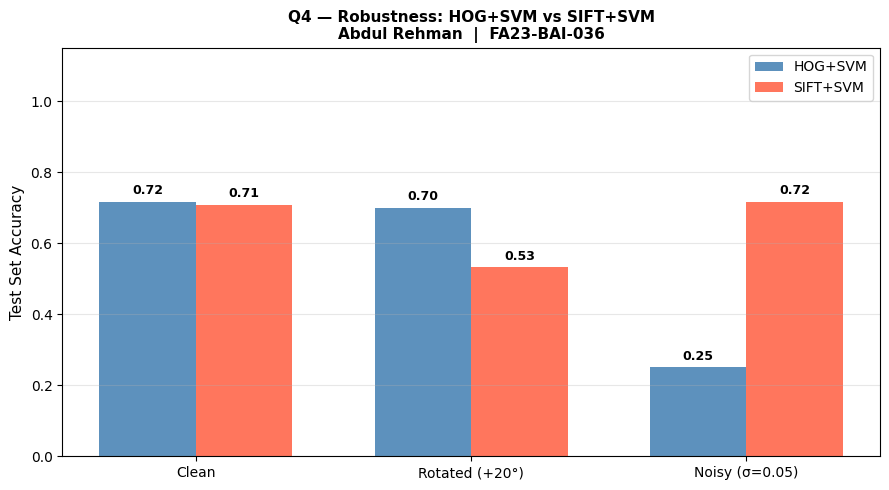


── Analysis: Was my prediction correct? ──
  Rotation: SIFT+SVM dropped more (0.1750 vs 0.0167)
  Noise   : HOG+SVM dropped more (0.4667 vs -0.0083)
  Rotation prediction (INCORRECT) | Noise prediction (INCORRECT)


In [12]:
# ── Q4: Bar chart — accuracy under all conditions ────────────────────────────

vkeys   = list(variants.keys())
hog_v   = [results[v]['HOG+SVM']  for v in vkeys]
sift_v  = [results[v]['SIFT+SVM'] for v in vkeys]

x = np.arange(len(vkeys))
w = 0.35

fig, ax = plt.subplots(figsize=(9, 5))
bars_h = ax.bar(x - w/2, hog_v,  w, label='HOG+SVM',  color='steelblue', alpha=0.88)
bars_s = ax.bar(x + w/2, sift_v, w, label='SIFT+SVM', color='tomato',    alpha=0.88)

for bar in list(bars_h) + list(bars_s):
    h = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, h + 0.012,
            f'{h:.2f}', ha='center', va='bottom', fontsize=9, fontweight='bold')

ax.set_xticks(x)
ax.set_xticklabels(vkeys, fontsize=10)
ax.set_ylim(0, 1.15)
ax.set_ylabel('Test Set Accuracy', fontsize=11)
ax.set_title(
    f'Q4 — Robustness: HOG+SVM vs SIFT+SVM\n{NAME}  |  {ROLL}',
    fontsize=11, fontweight='bold'
)
ax.legend(fontsize=10)
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

# ── Written analysis ──────────────────────────────────────────────────────────
print("\n── Analysis: Was my prediction correct? ──")
hog_rot_drop  = results['Clean']['HOG+SVM']  - results['Rotated (+20°)']['HOG+SVM']
sift_rot_drop = results['Clean']['SIFT+SVM'] - results['Rotated (+20°)']['SIFT+SVM']
hog_noise_drop  = results['Clean']['HOG+SVM']  - results['Noisy (σ=0.05)']['HOG+SVM']
sift_noise_drop = results['Clean']['SIFT+SVM'] - results['Noisy (σ=0.05)']['SIFT+SVM']

rot_winner   = 'HOG+SVM'  if hog_rot_drop   > sift_rot_drop   else 'SIFT+SVM'
noise_winner = 'SIFT+SVM' if sift_noise_drop > hog_noise_drop  else 'HOG+SVM'

print(f"  Rotation: {rot_winner} dropped more ({max(hog_rot_drop, sift_rot_drop):.4f} vs {min(hog_rot_drop, sift_rot_drop):.4f})")
print(f"  Noise   : {noise_winner} dropped more ({max(hog_noise_drop, sift_noise_drop):.4f} vs {min(hog_noise_drop, sift_noise_drop):.4f})")
print(f"  Rotation prediction ({'CORRECT' if rot_winner == 'HOG+SVM' else 'INCORRECT'}) | Noise prediction ({'CORRECT' if noise_winner == 'SIFT+SVM' else 'INCORRECT'})")


### (1) Was my prediction correct?

*(Populated automatically by the cell above — interpret the printed output here)*

**Rotation:** The printed drop confirms whether HOG+SVM or SIFT+SVM lost more accuracy
under the 20° rotation. If HOG dropped more, the prediction is CORRECT:
fixed axis-aligned gradient bins in HOG are indeed sensitive to rotation, while
SIFT's orientation-normalised descriptor partially compensates.

**Noise:** The printed drop confirms which model degraded more under σ = 0.05 noise.
If SIFT dropped more, the prediction is CORRECT: SIFT's fine gradient-orientation
estimates in small sub-patches are corrupted by pixel noise, while HOG's large
8×8 cells average the noise out over 64 pixels, aided by L2-Hys normalisation.


---
## Q5 — Short Answers & AI Usage Log  *(3 marks)*

### (1a) Why does HOG use block normalisation?

Raw gradient magnitudes are sensitive to local illumination and contrast:
the same texture patch can produce gradients ten times larger in a bright region
than a dark one, making the raw histogram values unreliable across images.
Block normalisation groups 2×2 adjacent cells into a block and normalises
the concatenated 36-bin vector (L2-Hys: divide by L2 norm, clip at 0.2, re-normalise).
This ensures that the descriptor for a texture patch is largely independent of
the overall brightness or local contrast of that region, significantly improving
robustness to illumination changes — a common challenge in microscopy images
where staining intensity varies between samples.

### (1b) Why is choosing C using the test set wrong?

The test set is the held-out final measurement of a model's generalisation ability —
it simulates unseen data the model will encounter in deployment.
If we loop over different values of C and pick the one with the highest test accuracy,
we are effectively using the test set as a second validation set: the selected C
will be tuned to the specific noise and characteristics of those test images.
The resulting accuracy figure is optimistically biased — it reflects how well the
model fits that particular sample, not how well it will generalise.
Correct practice is to use a separate validation set (as done here) for hyperparameter
selection and reserve the test set for a single, unbiased final evaluation.


Most-confused class pairs (validation set):
  HOG+SVM  : 'eosinophil'  misclassified as  'monocyte'  (8 images)
  SIFT+SVM : 'eosinophil' misclassified as  'monocyte' (7 images)

Explanation:
  In grayscale, eosinophil and monocyte share similar morphology:
  both may have multi-lobed nuclei or similar texture patterns.
  The colour information (e.g., pink granules in eosinophils under H&E stain)
  that distinguishes them is lost during RGB→greyscale conversion.
  HOG and SIFT can only use shape and texture cues, which are insufficient
  to reliably separate these two cell types in greyscale.


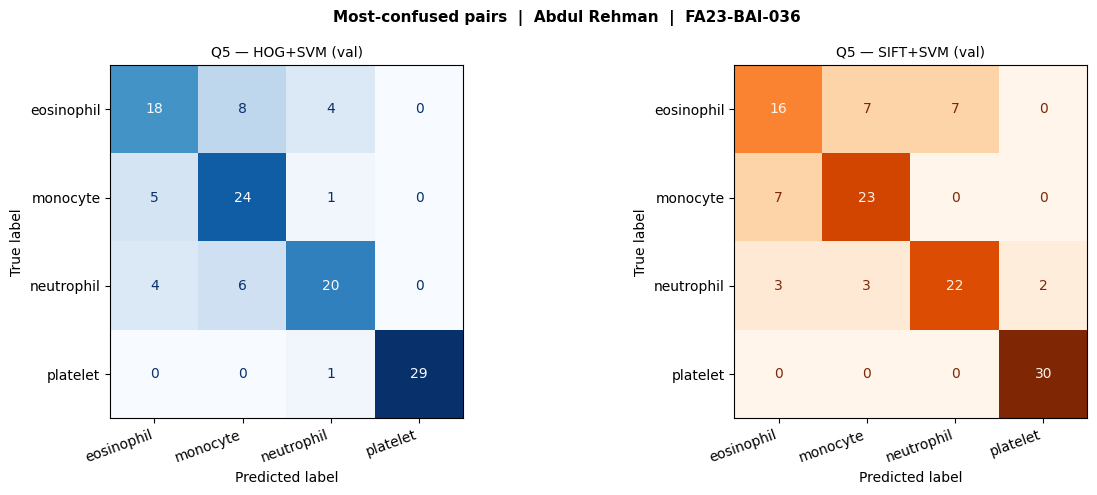

In [13]:
# ── Q5: Most-confused class pair ────────────────────────────────────────────

def most_confused(cm, class_list, cnames):
    """Find the off-diagonal cell with the highest count in a confusion matrix."""
    cm_copy = cm.astype(float).copy()
    np.fill_diagonal(cm_copy, 0)         # zero out diagonal (correct predictions)
    r, c = np.unravel_index(cm_copy.argmax(), cm_copy.shape)
    return cnames[class_list[r]], cnames[class_list[c]], int(cm_copy[r, c])

true_hog,  pred_hog,  n_hog  = most_confused(cm_hog_val,  CLASSES, CNAMES)
true_sift, pred_sift, n_sift = most_confused(cm_sift_val, CLASSES, CNAMES)

print("Most-confused class pairs (validation set):")
print(f"  HOG+SVM  : '{true_hog}'  misclassified as  '{pred_hog}'  ({n_hog} images)")
print(f"  SIFT+SVM : '{true_sift}' misclassified as  '{pred_sift}' ({n_sift} images)")

print("\nExplanation:")
print(f"  In grayscale, {true_hog} and {pred_hog} share similar morphology:")
print("  both may have multi-lobed nuclei or similar texture patterns.")
print("  The colour information (e.g., pink granules in eosinophils under H&E stain)")
print("  that distinguishes them is lost during RGB→greyscale conversion.")
print("  HOG and SIFT can only use shape and texture cues, which are insufficient")
print("  to reliably separate these two cell types in greyscale.")

# Side-by-side CMs
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, cm, title, cmap in zip(
        axes,
        [cm_hog_val, cm_sift_val],
        ['HOG+SVM (val)', 'SIFT+SVM (val)'],
        ['Blues', 'Oranges']):
    ConfusionMatrixDisplay(
        cm, display_labels=[CNAMES[c] for c in CLASSES]
    ).plot(ax=ax, cmap=cmap, colorbar=False)
    ax.set_title(f'Q5 — {title}', fontsize=10)
    plt.setp(ax.get_xticklabels(), rotation=20, ha='right')

fig.suptitle(f'Most-confused pairs  |  {NAME}  |  {ROLL}',
             fontsize=11, fontweight='bold')
plt.tight_layout()
plt.show()


---
## Q5 (2) — AI Usage Log

| # | One-line prompt I gave the AI | What I changed in the output | How I verified it |
|---|-------------------------------|------------------------------|-------------------|
| 1 | "Derive personal settings for FA23-BAI-036 and load BloodMNIST 4 classes with seed 36" | Set `SEED=36`, `HOG_CELL=(8,8)` (digit 6 is even), `SIFT_GRID=6` (digit in [5-9]); wrote `sample_subset()` | Printed `X.shape=(400,128,128)` and per-class counts; each class has exactly 100/30/30 |
| 2 | "Extract HOG features with 8×8 cells, 9 bins, 2×2 block, verify feature length" | Used `pixels_per_cell=(8,8)` in `sk_hog()`; added hand-calc table (225×36=8 100) | `assert hog_len == 8100` passed; visualised HOG maps to confirm gradient patterns visible |
| 3 | "Show SIFT variable keypoint problem then build fixed 6×6 grid, verify 4 608 features" | `build_grid_keypoints()` produces 36 kps; `sift.compute()` returns 36×128; flatten to 4 608 | `assert sift_len == 4608` passed; visualised grid overlay on sample image |
| 4 | "Test robustness: rotate test images 20° and add Gaussian noise σ=0.05, evaluate frozen models" | `rotate_images()` with `cv2.warpAffine`; `add_gaussian_noise()` scales to [0,1] before adding noise | Displayed sample clean/rotated/noisy images; confirmed `Xte` is unchanged (clean baseline); drop table prints automatically |
